# Unit VI Practical: Evaluating Unsupervised Models and an End-to-End Case Study

**Aim:** To judge the quality of clustering results using validation metrics, visualization and stability analysis,
and to build a complete unsupervised learning solution for a real healthcare dataset.

### Practicals covered
| Practical | Task | Dataset |
|---|---|---|
| 13 | Assess clustering quality with validation metrics, visualization and stability analysis; select a model | Wine |
| 14 | End-to-end solution: preprocessing, clustering, dimensionality reduction, anomaly detection, evaluation, insights | Breast Cancer (healthcare) |

### Syllabus covered
- Internal and external clustering validation metrics
- Silhouette score and the cohesion–separation intuition
- Stability-based evaluation
- Interpretability challenges, a real-world case study, ethical considerations

> Run the cells from top to bottom. Each output is followed by a short note on **what to look for**.

In [1]:
# Step 1: Import libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine, load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.ensemble import IsolationForest
from sklearn.metrics import (silhouette_score, silhouette_samples, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score,
                             normalized_mutual_info_score)

pd.set_option("display.width", 140)
print("Libraries imported successfully!")

Libraries imported successfully!


# Practical 13 – Assessing the Quality of Clustering

## 1. The problem: there is no "answer key"

In supervised learning we compare predictions with the true labels. In unsupervised learning there are usually
**no labels**, so how do we know if the clusters are good? We use three kinds of checks:

| Check | Needs true labels? | Question it answers |
|---|---|---|
| **Internal metrics** | No | Are the clusters tight and well separated? |
| **External metrics** | Yes | Do the clusters agree with known groups? |
| **Stability** | No | Do we get the same clusters if the data changes slightly? |

## 2. Load and standardize the Wine dataset

178 wines, 13 chemical features. The 3 cultivars are known, so we can also try **external** metrics.
In real projects such labels are often missing.

In [2]:
wine = load_wine(as_frame=True)
X = StandardScaler().fit_transform(wine.data)
true_cultivar = wine.target.values

print("Dataset shape:", X.shape)

Dataset shape: (178, 13)


## 3. Internal metrics (no labels needed)

| Metric | Range | Better when | Intuition |
|---|---|---|---|
| **Silhouette** | −1 to 1 | Higher | Each point is closer to its own cluster than to the next one |
| **Davies–Bouldin** | 0 and up | **Lower** | Clusters are small compared with the distance between them |
| **Calinski–Harabasz** | 0 and up | Higher | Spread **between** clusters is large compared with spread **within** them |

We compute all three for K-Means with k = 2 to 7.

In [3]:
rows = []
for k in range(2, 8):
    labels = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(X)
    rows.append({
        "k": k,
        "Silhouette (higher)": round(silhouette_score(X, labels), 3),
        "Davies-Bouldin (lower)": round(davies_bouldin_score(X, labels), 3),
        "Calinski-Harabasz (higher)": round(calinski_harabasz_score(X, labels), 1),
    })
internal = pd.DataFrame(rows).set_index("k")
internal

,Silhouette (higher),Davies-Bouldin (lower),Calinski-Harabasz (higher)
k,,,
2,0.259,1.526,69.5
3,0.285,1.389,70.9
4,0.260,1.797,56.2
5,0.202,1.808,47.0
6,0.237,1.554,41.7
7,0.204,1.661,38.7


**What to look for:** all three metrics agree that **k = 3** is best (highest silhouette, lowest Davies–Bouldin,
highest Calinski–Harabasz). When different metrics agree, we can be more confident in the choice.

## 4. Cohesion and separation: the silhouette plot

The silhouette value of one point is

$$ s = \frac{b - a}{\max(a, b)} $$

- **a** (cohesion) = average distance to the other points in its **own** cluster
- **b** (separation) = average distance to the points in the **nearest other** cluster

If **a is small and b is large**, s is close to 1. A negative s means the point is probably in the wrong cluster.
The plot below shows the silhouette value of **every** wine, grouped by cluster.

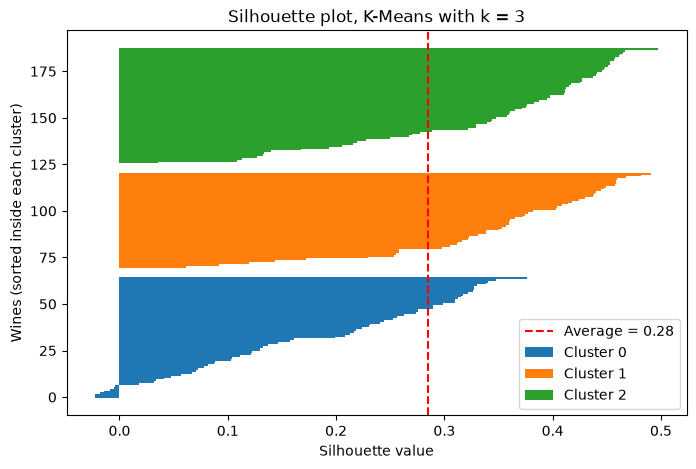

Wines with a negative silhouette value: 7 of 178


In [4]:
labels_k3 = KMeans(n_clusters=3, n_init=10, random_state=42).fit_predict(X)
s_values = silhouette_samples(X, labels_k3)

plt.figure(figsize=(8, 5))
y_start = 0
for c in range(3):
    vals = np.sort(s_values[labels_k3 == c])
    plt.barh(range(y_start, y_start + len(vals)), vals, height=1.0, label=f"Cluster {c}")
    y_start += len(vals) + 5
plt.axvline(s_values.mean(), color="red", linestyle="--", label=f"Average = {s_values.mean():.2f}")
plt.xlabel("Silhouette value")
plt.ylabel("Wines (sorted inside each cluster)")
plt.title("Silhouette plot, K-Means with k = 3")
plt.legend()
plt.show()

print("Wines with a negative silhouette value:", int((s_values < 0).sum()), "of", len(s_values))

**What to look for:** each cluster is a thick bar mostly to the right of 0, so the clusters are reasonably
cohesive and separated. The few bars below 0 are wines that sit between two clusters.

## 5. External metrics (only when true groups are known)

| Metric | Range | Meaning |
|---|---|---|
| **Adjusted Rand Index (ARI)** | about 0 (random) to 1 (perfect) | Do pairs of points that belong together end up together? |
| **Normalized Mutual Information (NMI)** | 0 to 1 | How much the clusters tell us about the true groups |

Both ignore the cluster **numbers** themselves (cluster "0" does not need to match cultivar "0").

In [5]:
print("ARI:", round(adjusted_rand_score(true_cultivar, labels_k3), 3))
print("NMI:", round(normalized_mutual_info_score(true_cultivar, labels_k3), 3))
pd.crosstab(true_cultivar, labels_k3, rownames=["True cultivar"], colnames=["Cluster"])

ARI: 0.897
NMI: 0.876


Cluster,0,1,2
True cultivar,,,
0,0,0,59
1,65,3,3
2,0,48,0


**What to look for:** a high ARI and NMI and a crosstab with one large number per row. The clusters found
without labels match the real cultivars closely.

## 6. Compare three algorithms

We run K-Means, Agglomerative (Ward) and DBSCAN and compare them with the same metrics.
DBSCAN may label some points as noise (`-1`); internal metrics are computed on the non-noise points.

In [6]:
models = {
    "K-Means (k=3)": KMeans(n_clusters=3, n_init=10, random_state=42),
    "Agglomerative Ward (k=3)": AgglomerativeClustering(n_clusters=3, linkage="ward"),
    "DBSCAN (eps=2.3, min_samples=5)": DBSCAN(eps=2.3, min_samples=5),
}

rows = []
all_labels = {}
for name, m in models.items():
    labels = m.fit_predict(X)
    all_labels[name] = labels
    kept = labels != -1
    n_clusters = len(set(labels[kept]))
    rows.append({
        "Model": name,
        "Clusters": n_clusters,
        "Noise points": int((~kept).sum()),
        "Silhouette": round(silhouette_score(X[kept], labels[kept]), 3) if n_clusters > 1 else None,
        "Davies-Bouldin": round(davies_bouldin_score(X[kept], labels[kept]), 3) if n_clusters > 1 else None,
        "ARI (vs cultivar)": round(adjusted_rand_score(true_cultivar, labels), 3),
    })
pd.DataFrame(rows)

,Model,Clusters,Noise points,Silhouette,Davies-Bouldin,ARI (vs cultivar)
0,K-Means (k=3),3,0,0.285,1.389,0.897
1,Agglomerative Ward (k=3),3,0,0.277,1.419,0.790
2,"DBSCAN (eps=2.3, min_samples=5)",2,42,0.331,1.182,0.384


**What to look for:**
- K-Means and Ward have similar internal scores; K-Means matches the cultivars a little better (higher ARI).
- **DBSCAN seems to have the best silhouette and Davies–Bouldin scores, but this is misleading.** Those scores are
  computed only on the wines that were **not** marked as noise, and DBSCAN found only **2** clusters.
  Its ARI shows it matches the real cultivars poorly. In 13 dimensions the density of the points is fairly even,
  so one `eps` value cannot separate the cultivars.

**Lesson:** an internal metric can look good for the wrong reason (here, by throwing difficult points away as noise).
Always read the number of clusters and noise points together with the scores.

## 7. Visual check

Metrics are summaries. Always **look** at the clusters too. PCA (Unit IV) is used only to draw them in 2D.

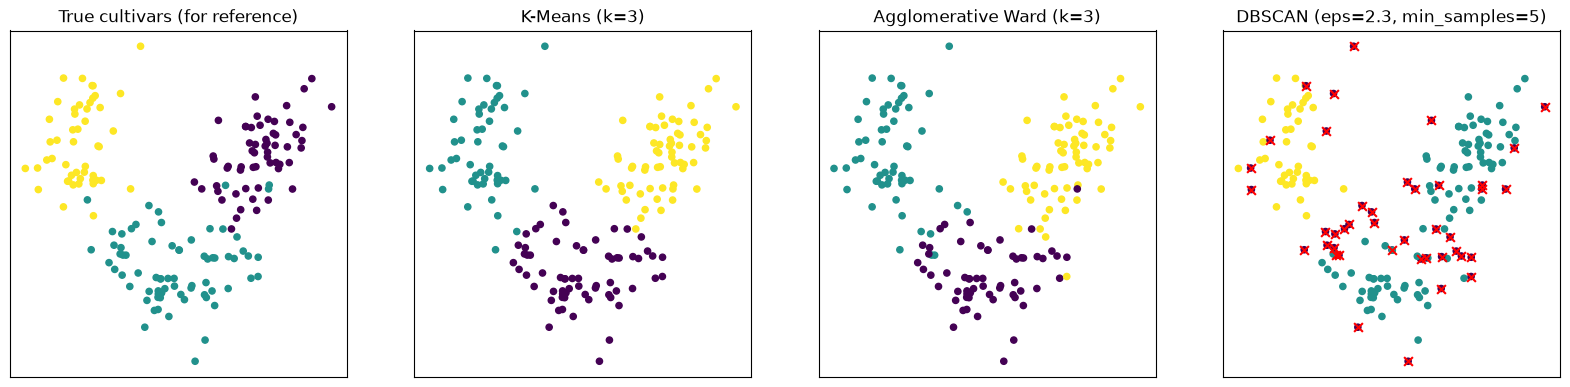

In [7]:
view = PCA(n_components=2, random_state=42).fit_transform(X)

fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
axes[0].scatter(view[:, 0], view[:, 1], c=true_cultivar, cmap="viridis", s=20)
axes[0].set_title("True cultivars (for reference)")
for ax, (name, labels) in zip(axes[1:], all_labels.items()):
    ax.scatter(view[:, 0], view[:, 1], c=labels, cmap="viridis", s=20)
    ax.scatter(view[labels == -1, 0], view[labels == -1, 1], c="red", marker="x", s=40, label="noise")
    ax.set_title(name)
for ax in axes:
    ax.set_xticks([])
    ax.set_yticks([])
plt.show()

## 8. Stability-based evaluation

A good clustering should **not change much** if the data changes slightly. We test this by **bootstrapping**:

1. Draw a random sample of the wines (with replacement).
2. Cluster the sample.
3. Compare its labels with the labels of the full-data clustering on the same wines, using ARI.
4. Repeat 30 times and look at the average and the spread.

In [8]:
def stability(make_model, n_rounds=30):
    reference = make_model().fit_predict(X)
    rng = np.random.default_rng(0)
    scores = []
    for _ in range(n_rounds):
        idx = rng.choice(len(X), size=len(X), replace=True)
        labels = make_model().fit_predict(X[idx])
        scores.append(adjusted_rand_score(reference[idx], labels))
    return np.array(scores)

rows = []
for k in range(2, 8):
    s = stability(lambda: KMeans(n_clusters=k, n_init=10, random_state=0))
    rows.append({"k": k, "Mean stability (ARI)": round(s.mean(), 3), "Spread (std)": round(s.std(), 3)})
stab = pd.DataFrame(rows).set_index("k")
stab

,Mean stability (ARI),Spread (std)
k,,
2,0.660,0.304
3,0.951,0.051
4,0.765,0.095
5,0.646,0.109
6,0.686,0.108
7,0.583,0.062


**What to look for:** **k = 3** is highly stable (average ARI close to 1, small spread): the same three clusters
appear again and again. With **k = 2** two real groups must be forced together, and the samples disagree on which
two, so stability is low and the spread is large. For **k ≥ 4** the extra clusters split the data in different
ways from one sample to the next, so the average ARI drops again. An unstable clustering should not be trusted.

## 9. Model selection – put the evidence together

In [9]:
summary = internal[["Silhouette (higher)", "Davies-Bouldin (lower)"]].join(stab["Mean stability (ARI)"])
summary

,Silhouette (higher),Davies-Bouldin (lower),Mean stability (ARI)
k,,,
2,0.259,1.526,0.660
3,0.285,1.389,0.951
4,0.260,1.797,0.765
5,0.202,1.808,0.646
6,0.237,1.554,0.686
7,0.204,1.661,0.583


**Decision:** **K-Means with k = 3** has the best internal metrics **and** is the most stable, and the visual check
agrees. That is the model we select. The external metrics (ARI/NMI) confirm it here only because the true
cultivars happen to be known.

### Practical 13 – Result
No single number decides the quality of a clustering. We combined **internal metrics**, a **silhouette plot**,
a **visual check** and **stability analysis**, and used external metrics only because labels were available.

# Practical 14 – End-to-End Case Study: Grouping Tumour Samples (Healthcare)

## 10. Problem statement

A hospital laboratory has measurements of 569 breast tumour samples (30 features each, computed from cell images).
It wants to know:

1. Are there **natural groups** of tumours with similar cell features?
2. Are there **unusual samples** that should be re-checked (possible measurement or data-entry errors)?
3. Can the groups be **explained** to doctors in simple terms?

The diagnosis (malignant / benign) exists in the dataset, but we **hide it** during the whole analysis and use it
only at the end to judge whether the groups are medically meaningful.

```text
 Raw data -> Clean & scale -> Anomaly screening -> PCA -> Clustering -> Evaluate -> Explain -> Report
```

## 11. Load and explore

In [10]:
cancer = load_breast_cancer(as_frame=True)
data = cancer.data.copy()
diagnosis = np.where(cancer.target == 0, "malignant", "benign")   # hidden until the end

print("Samples:", data.shape[0], "  Features:", data.shape[1])
print("Missing values:", int(data.isna().sum().sum()))
data[["mean radius", "mean texture", "mean area", "mean concavity", "worst radius"]].describe().round(2)

Samples: 569   Features: 30
Missing values: 0


,mean radius,mean texture,mean area,mean concavity,worst radius
count,569.00,569.00,569.00,569.00,569.00
mean,14.13,19.29,654.89,0.09,16.27
std,3.52,4.30,351.91,0.08,4.83
min,6.98,9.71,143.50,0.00,7.93
25%,11.70,16.17,420.30,0.03,13.01
50%,13.37,18.84,551.10,0.06,14.97
75%,15.78,21.80,782.70,0.13,18.79
max,28.11,39.28,2501.00,0.43,36.04


**What to look for:** no missing values, but the features have very different ranges (for example
`mean area` is in the hundreds, `mean concavity` is below 1). So scaling is required.

## 12. Preprocess: scale the features

In [11]:
X_med = StandardScaler().fit_transform(data)
print("Scaled data shape:", X_med.shape)

Scaled data shape: (569, 30)


## 13. Anomaly screening with Isolation Forest (Unit V)

Before clustering, we flag the most unusual 2 % of samples for a manual re-check.
They stay in the data (they may be real, rare tumours), but we report them to the lab.

In [12]:
iso = IsolationForest(n_estimators=300, contamination=0.02, random_state=42).fit(X_med)
unusual = iso.predict(X_med) == -1

print("Samples flagged for re-check:", int(unusual.sum()))
data.loc[unusual, ["mean radius", "mean area", "mean concavity", "worst area"]].round(2)

Samples flagged for re-check: 12


,mean radius,mean area,mean concavity,worst area
3,11.42,386.1,0.24,567.7
12,19.17,1123.0,0.21,1332.0
68,9.03,250.5,0.31,324.7
78,20.18,1245.0,0.38,1623.0
82,25.22,1878.0,0.33,2562.0
108,22.27,1509.0,0.43,2360.0
122,24.25,1761.0,0.43,2073.0
152,9.73,300.2,0.41,380.5
212,28.11,2499.0,0.32,2499.0
258,15.66,773.5,0.32,1226.0


**What to look for:** the flagged samples have unusual combinations of values. Some are **very large**
(area far above the average of about 655), and some are **small but very irregular** (high concavity).
In a real project, a lab technician would confirm whether these readings are correct.

## 14. Dimensionality reduction with PCA (Unit IV)

30 features are many, and several of them measure the same thing (radius, perimeter and area are strongly related).
We keep enough principal components to explain **90 %** of the variance.

In [13]:
pca = PCA(n_components=0.90, random_state=42)
X_red = pca.fit_transform(X_med)

print("Features before PCA:", X_med.shape[1])
print("Components kept    :", X_red.shape[1])
print("Variance kept      :", round(pca.explained_variance_ratio_.sum() * 100, 1), "%")

Features before PCA: 30
Components kept    : 7
Variance kept      : 91.0 %


## 15. Choose the number of clusters (Practical 13 methods)

In [14]:
rows = []
for k in range(2, 7):
    labels = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(X_red)
    rows.append({"k": k,
                 "Silhouette": round(silhouette_score(X_red, labels), 3),
                 "Davies-Bouldin": round(davies_bouldin_score(X_red, labels), 3)})
pd.DataFrame(rows).set_index("k")

,Silhouette,Davies-Bouldin
k,,
2,0.371,1.216
3,0.338,1.404
4,0.312,1.360
5,0.191,1.589
6,0.189,1.533


**What to look for:** **k = 2** has the best silhouette and the lowest Davies–Bouldin, so we use two clusters.

## 16. Cluster and visualize

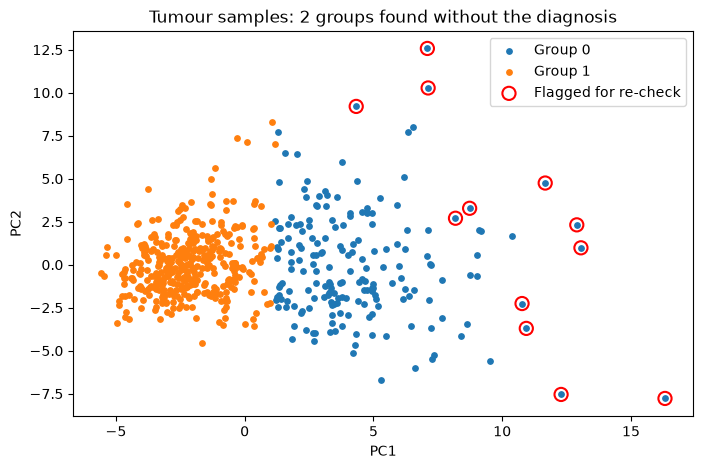

0    189
1    380
Name: samples per group, dtype: int64


In [15]:
kmeans = KMeans(n_clusters=2, n_init=10, random_state=42)
group = kmeans.fit_predict(X_red)

plt.figure(figsize=(8, 5))
for g in range(2):
    plt.scatter(X_red[group == g, 0], X_red[group == g, 1], s=15, label=f"Group {g}")
plt.scatter(X_red[unusual, 0], X_red[unusual, 1], s=90, facecolors="none", edgecolors="red",
            linewidths=1.5, label="Flagged for re-check")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Tumour samples: 2 groups found without the diagnosis")
plt.legend()
plt.show()

print(pd.Series(group).value_counts().sort_index().rename("samples per group"))

## 17. Explain the groups (interpretability)

A cluster number means nothing to a doctor. We describe each group by its **average values** of a few
understandable features, in the original units.

In [16]:
profile_cols = ["mean radius", "mean area", "mean concavity", "mean concave points", "mean texture"]
profile = data[profile_cols].groupby(group).mean().round(3)
profile.index = [f"Group {g}" for g in profile.index]
profile

,mean radius,mean area,mean concavity,mean concave points,mean texture
Group 0,17.557,993.67,0.180,0.094,21.359
Group 1,12.422,486.39,0.044,0.026,18.260


**What to look for:** one group has clearly **larger** cells (radius, area) with **more concave (irregular)**
outlines. In plain words: *"Group A: small, smooth, regular cells. Group B: large, irregular cells."*
This kind of description is what makes clusters useful to non-experts.

## 18. Evaluate against the hidden diagnosis

Only now do we bring back the diagnosis.

In [17]:
print("ARI:", round(adjusted_rand_score(diagnosis, group), 3))
print("NMI:", round(normalized_mutual_info_score(diagnosis, group), 3))
pd.crosstab(diagnosis, group, rownames=["Diagnosis"], colnames=["Group"])

ARI: 0.671
NMI: 0.555


Group,0,1
Diagnosis,,
benign,14,343
malignant,175,37


**What to look for:** most benign samples fall in one group and most malignant samples in the other.
The unsupervised groups match the medical diagnosis well, although not perfectly: some samples sit in the
"wrong" group, which is why clustering can **support** but never **replace** a diagnosis.

## 19. Insights to present

1. The samples form **two natural groups**: small, regular cells and large, irregular cells.
2. These groups agree strongly with the diagnosis, even though the diagnosis was never used.
3. A small number of samples were flagged as unusual and should be re-checked by the lab.
4. 30 features can be summarised with a few principal components without losing much information.

## 20. Ethical considerations in pattern discovery

| Concern | In this case study |
|---|---|
| **Privacy** | Patient data must be anonymised and stored securely; results should not identify individuals |
| **Misuse of clusters** | A cluster label is **not a diagnosis**. Decisions must be made by qualified doctors |
| **Bias** | If the samples come from one hospital or population, the groups may not hold elsewhere |
| **Interpretability** | Clusters must be explained in medical terms before anyone acts on them |
| **Unusual cases** | Flagged samples may be rare real cases; they should be reviewed, not deleted |

## Conclusion

In Practical 13 we judged clustering quality without an answer key by combining internal metrics, the silhouette
plot, a visual check and stability analysis, and selected K-Means with k = 3 for the wine data.
In Practical 14 we built a complete pipeline on real healthcare data: scaling, anomaly screening with Isolation
Forest, PCA, K-Means, evaluation and plain-language cluster profiles. The groups found without labels matched the
diagnosis closely, and the ethical limits of using such patterns were made clear.